<style>
@page { size: A4; margin: 10mm 12mm 11mm 12mm; }
@media print {
  .code_cell .input, div.prompt, .jp-CodeCell .jp-InputArea { display: none !important; }
  .page-break { break-before: page; page-break-before: always; }
  .jp-OutputArea-output { break-inside: avoid; page-break-inside: avoid; }
  h1, h2, h3 { break-after: avoid; page-break-after: avoid; }
}
.page-break { height: 0; }
body { color: #172554; }
h1 { color: #172554; border-bottom: 3px solid #06B6D4; padding-bottom: 6px; }
h2 { color: #2563EB; }
.report-note { background: #F1F5F9; border-left: 5px solid #06B6D4; padding: 10px 14px; margin: 8px 0 14px 0; }
.finding { background: #FFF7ED; border-left: 5px solid #F97316; padding: 10px 14px; margin: 8px 0 14px 0; }
table { font-size: 9.5pt !important; }
</style>

# Phase I high-school exploratory analysis

## AI literacy and socioeconomic background

This report combines the Phase I responses from Invictus and STTSS. Every plot and comparison uses the same **20 students with complete socioeconomic information**. The report describes patterns in these students and does not estimate causal effects.


**Sample used.** All results below use the same **20 students**. Of these, **7 had prior AI-course experience** and **13 did not**.

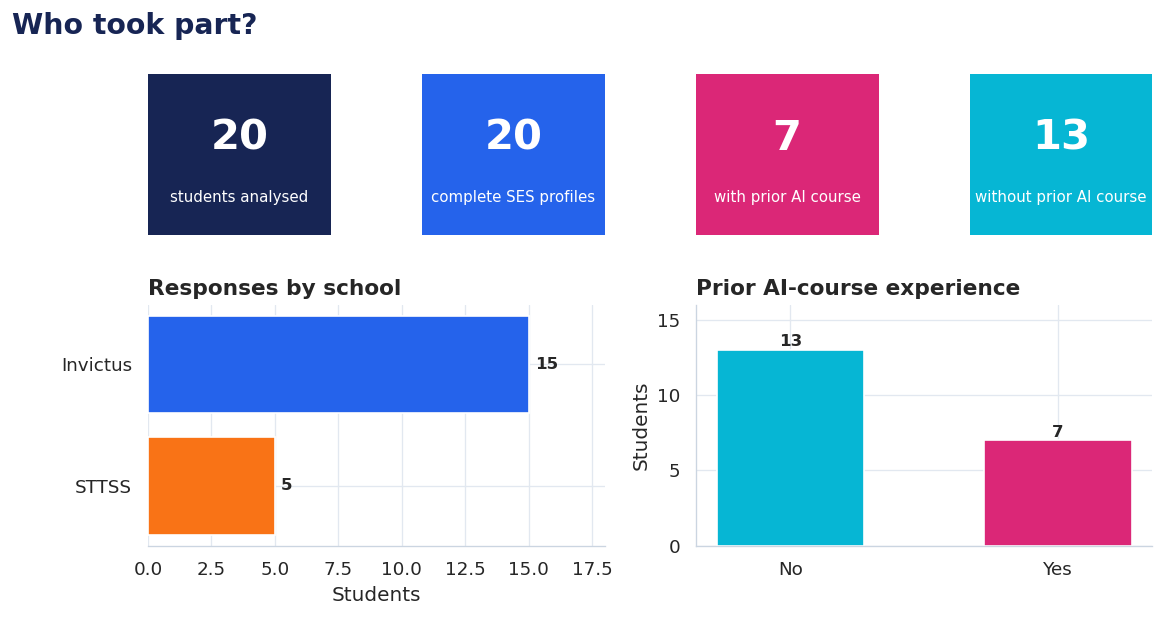

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/private/tmp/matplotlib-hs')

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from functions import AI_EFA_ITEMS, cronbach_alpha, mediator_map
from functions_HS import (
    AI_FACTOR_LABELS, MEDIATOR_LABELS, SES_FACTOR_LABELS,
    ai_idea_consistency, ai_item_profile, compact_test_table, compare_ses_groups,
    construct_descriptives, continuous_associations, plot_ai_item_profile,
    plot_association_matrix, plot_effect_sizes, plot_overall_distributions,
    plot_analysis_workflow, plot_overview, plot_preprocessing_flowchart,
    plot_score_construction_tree, plot_ses_group_comparisons, prepare_hs_analysis,
    prior_course_fisher_tests, sample_overview, set_report_style,
)

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:.2f}')
set_report_style()

# Keep one common analysis sample, then place the four EFA scores on a scale
# centred on these 20 students. This preserves the EFA dimensions while making
# every displayed comparison internal to the high-school sample.
df_all, _efa_model = prepare_hs_analysis()
df = df_all.dropna(subset=['ses_education', 'ses_resources']).copy().reset_index(drop=True)
factor_scores = ['ai_understanding', 'ai_confidence', 'ses_education', 'ses_resources']
for score in factor_scores:
    spread = df[score].std(ddof=0)
    df[score] = (df[score] - df[score].mean()) / spread

overview = sample_overview(df)
descriptives = construct_descriptives(df)
item_results = ai_item_profile(df)
group_tests = compare_ses_groups(df)
associations = continuous_associations(df)
course_tests = prior_course_fisher_tests(df)

plot_overview(df)
display(Markdown(
    f"**Sample used.** All results below use the same **{len(df)} students**. "
    f"Of these, **{int(df['ai_course_taken_num'].eq(1).sum())} had prior AI-course experience** and "
    f"**{int(df['ai_course_taken_num'].eq(0).sum())} did not**."
))


<div class="page-break"></div>

# How the scores were constructed

This section shows how raw questionnaire answers become analysis-ready variables.

### Three preprocessing routes

- **AI literacy:** Ten questions cover five Big Ideas. Each idea has one **understanding** question and one **confidence or ability** question. After reverse-keying where required, EFA reduces these questions to two broader factors.
- **Socioeconomic background:** Six measures describing parental education and household resources are reduced by EFA to two SES factors.
- **Mediators:** Ten questions form five two-question averages: **conceptual exposure**, **practical AI use**, **learning ecology**, **language difficulty**, and **evaluative stance**.

### What mediators are used for

Mediators represent learning experiences that may help explain **how socioeconomic background becomes connected with AI literacy**. For example, SES may shape students' opportunities to use AI, the language difficulty they face, or their habit of evaluating information.

The current report retains **practical AI use**, **language difficulty**, and **evaluative stance**. Conceptual exposure and learning ecology remain shown in the preprocessing record but are not carried into the current comparisons. With only 20 students, these variables are explored descriptively; they are **not used to claim a causal pathway**.

The four EFA factors are centred on these **20 students**, so **zero means the group average**.


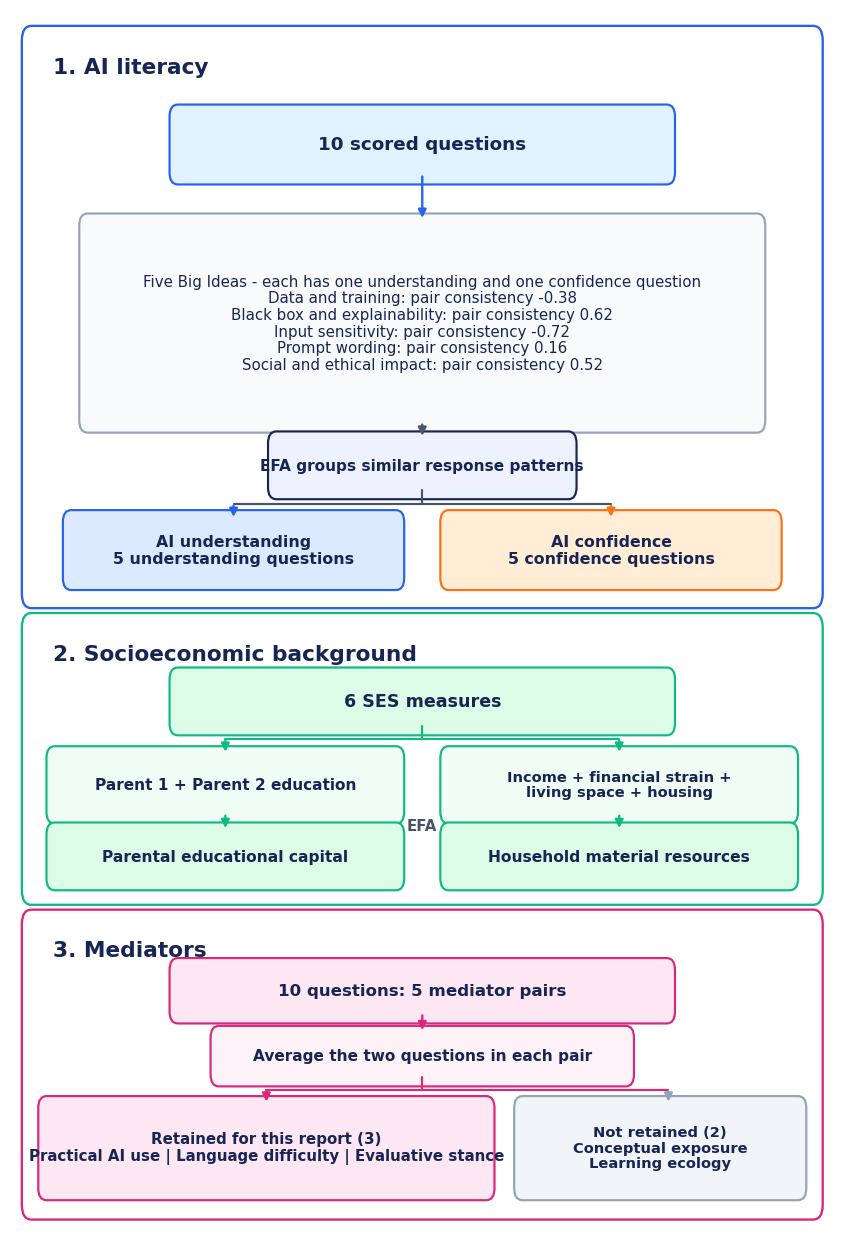

**How to read consistency.** Each value compares the **two questions within one AI Big Idea**. A value closer to 1 means that understanding and confidence move together; a negative value means that they often move in opposite directions. The closest pair in this sample is **black box and explainability**. This pattern supports keeping **AI understanding** and **AI confidence** as separate EFA factors.

In [2]:
idea_consistency = ai_idea_consistency(df)
preprocessing_figure = plot_preprocessing_flowchart(idea_consistency)
display(preprocessing_figure)
plt.close(preprocessing_figure)

strongest_pair = idea_consistency.loc[idea_consistency['Cronbach alpha'].idxmax()]
display(Markdown(
    "**How to read consistency.** Each value compares the **two questions within one AI Big Idea**. "
    "A value closer to 1 means that understanding and confidence move together; a negative value means that they often move in opposite directions. "
    f"The closest pair in this sample is **{strongest_pair['Big Idea'].lower()}**. This pattern supports keeping "
    "**AI understanding** and **AI confidence** as separate EFA factors."
))


<div class="page-break"></div>

# How the variables enter the analysis

The diagram below shows how the three prepared variable families enter the analysis. **SES factors** are the explanatory variables, while the two **AI-literacy factors** and three retained **mediators** form five modeled outcomes. In this 20-student report, mediators describe possible connecting experiences; they are not used to estimate a causal pathway.


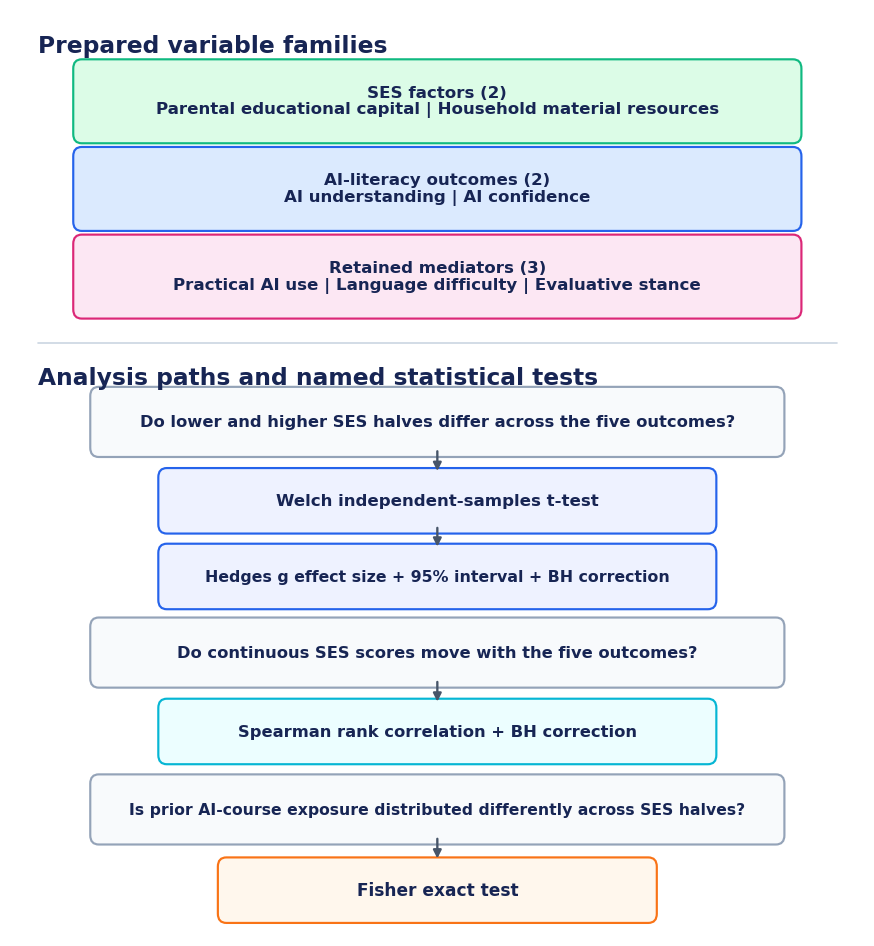

In [3]:
analysis_figure = plot_analysis_workflow()
display(analysis_figure)
plt.close(analysis_figure)


<div class="page-break"></div>

# Overall AI literacy and learning experiences

How to read the plots:

- **Each dot** represents one student.
- The wider part of each coloured shape shows where **more students are clustered**; the box marks the middle half of the group.
- For the two AI summaries, **zero is the average of these 20 students**.
- For the three learning-experience scores, the dashed line at **3 is the midpoint** of the 1-to-5 scale.


**Interpretation.** Both AI summaries show **meaningful differences between individual students**, even though their group average is set to zero. Students report **moderate practical AI use** (**3.38/5**) and a **moderate habit of checking information** (**3.38/5**). Average **language difficulty** is **2.80/5**, and its wide spread shows that this is a much larger barrier for some students than for others.

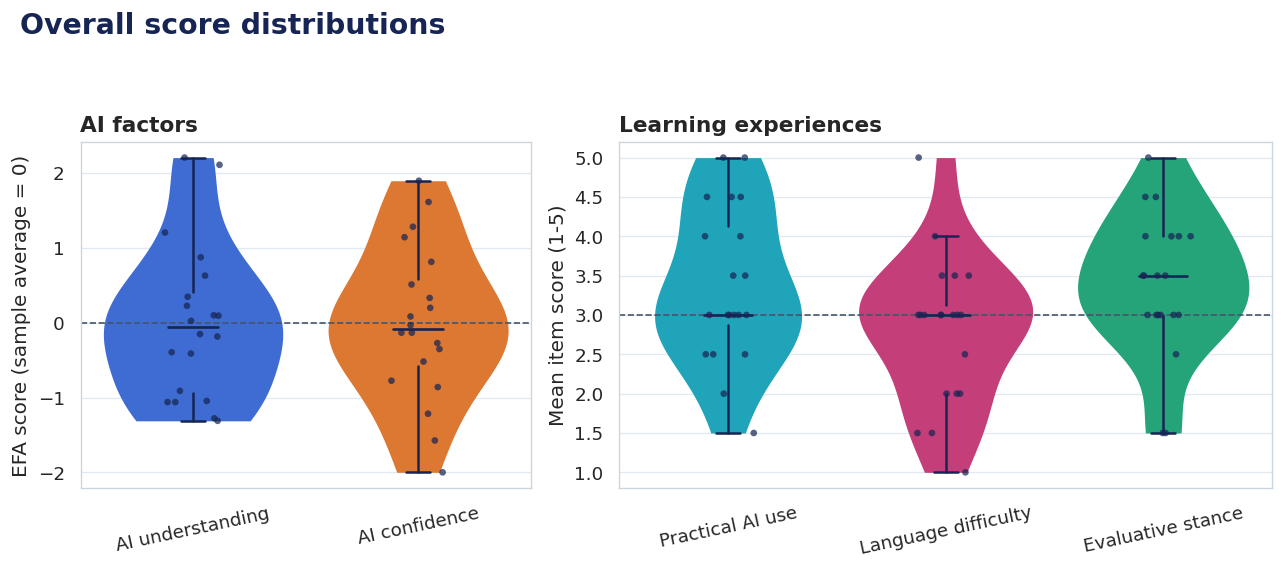

In [4]:
plot_overall_distributions(df)

ai_u = descriptives.set_index('measure').loc['ai_understanding']
ai_c = descriptives.set_index('measure').loc['ai_confidence']
practical = descriptives.set_index('measure').loc['practical_ai_use_score']
language = descriptives.set_index('measure').loc['language_load_score']
epistemic = descriptives.set_index('measure').loc['epistemic_stance_score']

display(Markdown(
    "**Interpretation.** Both AI summaries show **meaningful differences between individual students**, even though their "
    "group average is set to zero. "
    f"Students report **moderate practical AI use** (**{practical['mean']:.2f}/5**) and a "
    f"**moderate habit of checking information** (**{epistemic['mean']:.2f}/5**). "
    f"Average **language difficulty** is **{language['mean']:.2f}/5**, and its wide spread shows that this is a much "
    "larger barrier for some students than for others."
))


<div class="page-break"></div>

# AI-literacy strengths and gaps by question

How to read the plot:

- Each dot is the **average response** to one AI-literacy question.
- The horizontal line around each dot shows the **uncertainty around that average**.
- Scores run from **1 to 5**, and a higher score means stronger understanding or confidence.
- The dashed line at **3** marks the scale midpoint.


**Interpretation.** The clearest **knowledge gaps** concern **recognises the black-box problem** (mean 2.50/5) and **recognises social and ethical limits** (mean 2.90/5). Students report their **strongest confidence** for **can address social and ethical issues** (4.30/5), **can write effective prompts** (4.20/5), and **can explain training data** (4.05/5). The difference between lower conceptual scores and higher confidence makes **direct checks of understanding** a useful teaching priority.

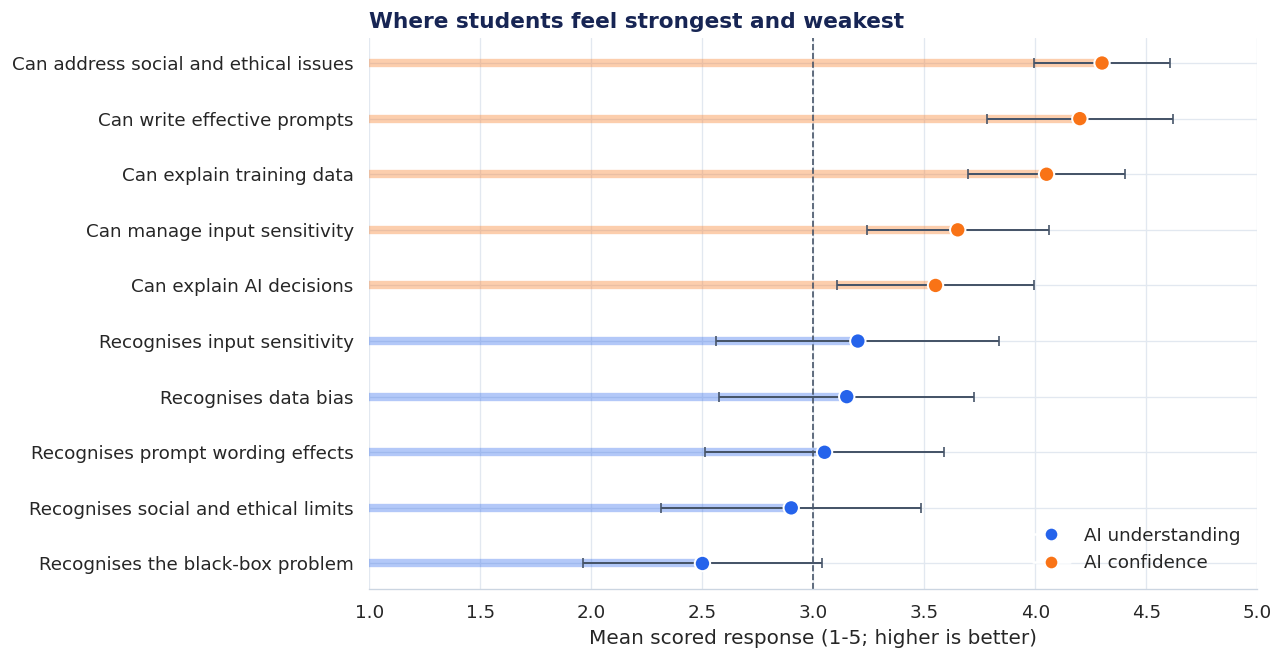

In [5]:
plot_ai_item_profile(item_results)
weak = item_results.nsmallest(2, 'mean')
strong = item_results.nlargest(3, 'mean')
display(Markdown(
    f"**Interpretation.** The clearest **knowledge gaps** concern **{weak.iloc[0]['Item'].lower()}** "
    f"(mean {weak.iloc[0]['mean']:.2f}/5) and **{weak.iloc[1]['Item'].lower()}** "
    f"(mean {weak.iloc[1]['mean']:.2f}/5). Students report their **strongest confidence** for "
    f"**{strong.iloc[0]['Item'].lower()}** ({strong.iloc[0]['mean']:.2f}/5), "
    f"**{strong.iloc[1]['Item'].lower()}** ({strong.iloc[1]['mean']:.2f}/5), and "
    f"**{strong.iloc[2]['Item'].lower()}** ({strong.iloc[2]['mean']:.2f}/5). "
    "The difference between lower conceptual scores and higher confidence makes **direct checks of understanding** a useful teaching priority."
))


<div class="page-break"></div>

# What differs between lower and higher SES groups?

How to read the plots:

- Each SES summary is divided into a **lower half** and a **higher half**, with 10 students in each group.
- **Each dot** is one student; the shape shows where scores are concentrated.
- Every outcome is placed on the same within-sample scale, where **zero is the average of these 20 students**.
- The split is a simple visual comparison, **not a policy threshold**.


**Interpretation.** The clearest visible pattern is **less language difficulty** among students in the higher parental-education group (an average gap of **0.90 points** on the 1-to-5 scale). This may mean that educational support at home helps students work through language demands. By contrast, **AI understanding and confidence look broadly similar** across both SES splits. The higher material-resource group reports a lower evaluative-stance mean by **0.75 points**, but this unexpected pattern is **too uncertain to interpret confidently** in such a small sample.

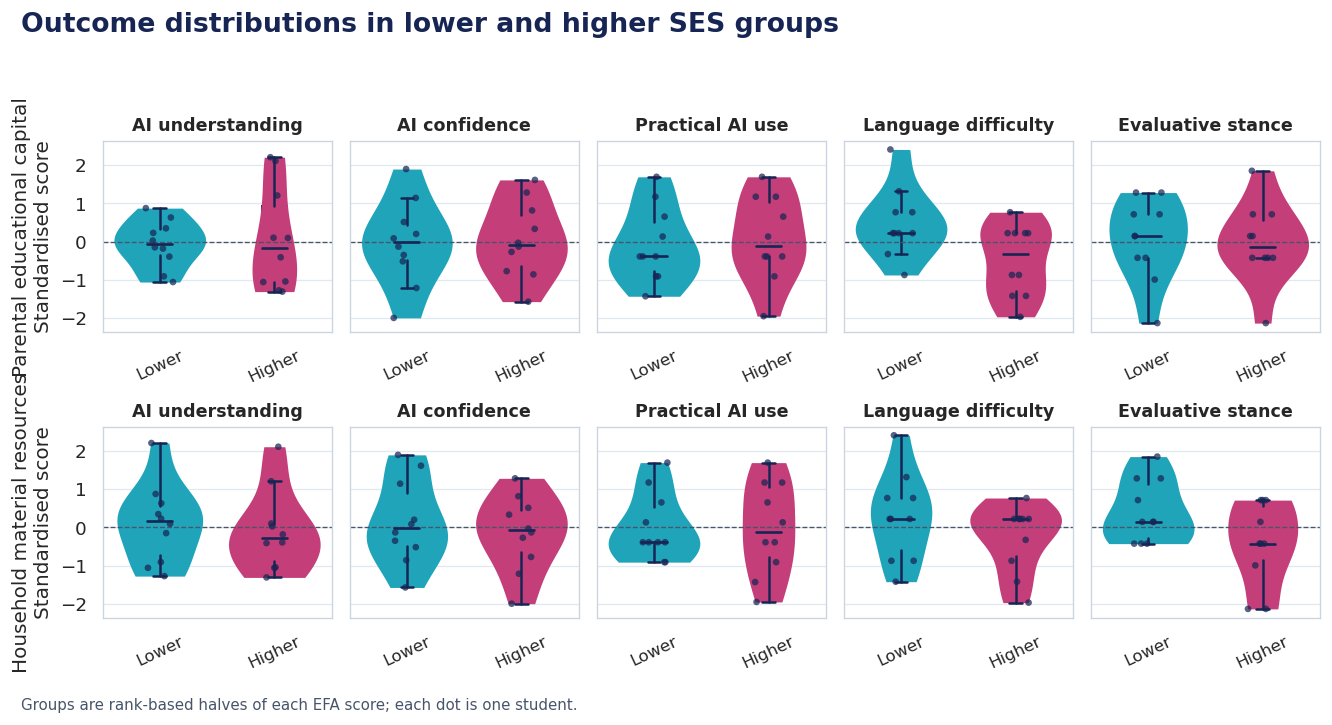

In [6]:
plot_ses_group_comparisons(df)

lang = group_tests.query("ses_factor == 'ses_education' and outcome == 'language_load_score'").iloc[0]
eval_row = group_tests.query("ses_factor == 'ses_resources' and outcome == 'epistemic_stance_score'").iloc[0]
display(Markdown(
    f"**Interpretation.** The clearest visible pattern is **less language difficulty** among students in the higher "
    f"parental-education group (an average gap of **{abs(lang['difference']):.2f} points** on the 1-to-5 scale). "
    "This may mean that educational support at home helps students work through language demands. "
    "By contrast, **AI understanding and confidence look broadly similar** across both SES splits. "
    f"The higher material-resource group reports a lower evaluative-stance mean by **{abs(eval_row['difference']):.2f} points**, "
    "but this unexpected pattern is **too uncertain to interpret confidently** in such a small sample."
))


<div class="page-break"></div>

# Exploratory statistical comparisons


Statistical methods used on this page:

- The **Welch independent-samples t-test** compares the average outcome between the lower and higher SES halves. It does not assume equal variation in the two groups.
- **Hedges g** describes the size and direction of each difference, with less small-sample bias than Cohen's d.
- Horizontal lines show the **95% confidence interval** around each effect-size estimate.
- **Benjamini-Hochberg (BH) correction** limits false discoveries across the five outcomes tested within each SES dimension.

On the plot, a dot to the **right of zero** means the higher-SES half scored higher; a dot to the left means it scored lower.


SES dimension,Outcome,Higher - lower,Effect size,p,BH p
Household material resources,AI confidence,-0.30,-0.27,0.530,0.854
Household material resources,Language difficulty,-0.50,-0.52,0.244,0.610
Household material resources,Evaluative stance,-0.75,-0.86,0.062,0.308
Parental educational capital,Language difficulty,-0.90,-1.03,0.027,0.137


**Interpretation.** **No group difference is firm** after accounting for the five outcomes examined within each SES dimension. The clearest signal is **language difficulty** across parental educational capital, but the wide range of plausible values means the real difference could be much smaller or larger. This is a **priority for a larger follow-up**, not a final conclusion.

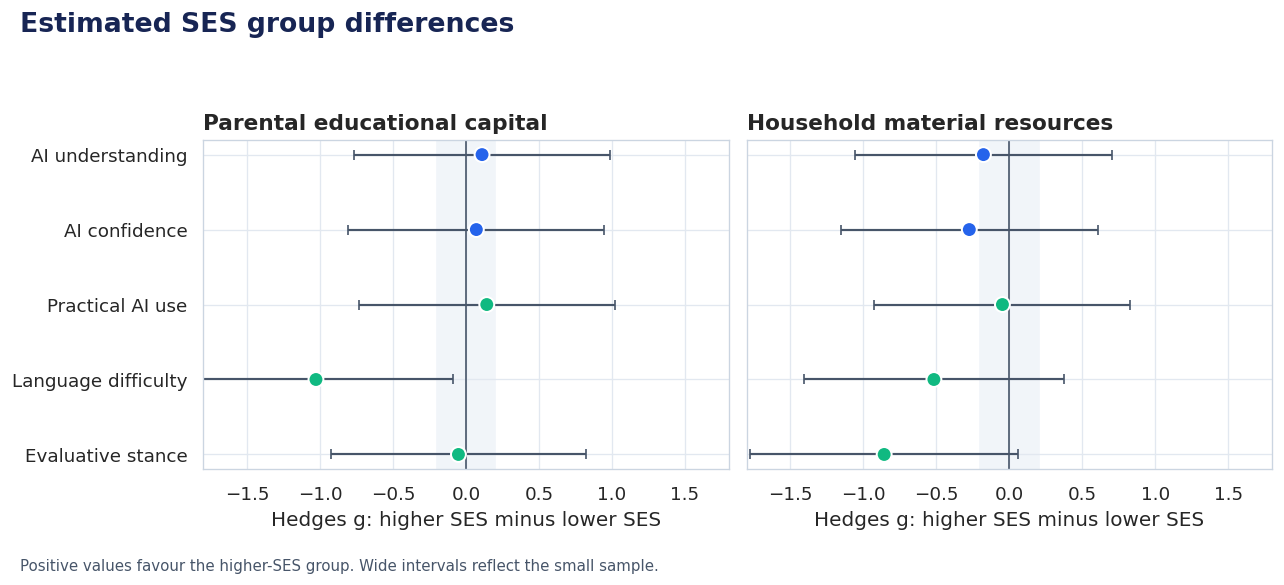

In [7]:
plot_effect_sizes(group_tests)

strongest_rows = group_tests['hedges_g'].abs().nlargest(4).index
reader_table = compact_test_table(group_tests.loc[strongest_rows])
reader_table = reader_table.sort_values('Effect size')
display(reader_table.style.hide_index())

best = group_tests.loc[group_tests['p_value'].idxmin()]
display(Markdown(
    f"**Interpretation.** **No group difference is firm** after accounting for the five outcomes examined within each SES dimension. "
    f"The clearest signal is **{best['Outcome'].lower()}** across {best['SES dimension'].lower()}, but the wide range of "
    "plausible values means the real difference could be much smaller or larger. This is a **priority for a larger follow-up**, "
    "not a final conclusion."
))


<div class="page-break"></div>

# Continuous patterns and prior AI-course exposure

Statistical methods used on this page:

- **Spearman rank correlation** tests whether a higher continuous SES score generally goes with a higher or lower outcome score. Larger circles show stronger relationships; magenta is positive and cyan is negative.
- **Benjamini-Hochberg correction** is applied across the five outcomes within each SES dimension.
- **Fisher's exact test** compares prior AI-course participation between the lower and higher SES halves; it is appropriate for the small cell counts in this sample.

These are **patterns within the 20 students** and do not establish cause and effect.


SES dimension,Lower SES with prior course,Higher SES with prior course,Fisher p
Parental educational capital,1/10,6/10,0.057
Household material resources,2/10,5/10,0.350


**Interpretation.** Students with more **parental educational capital** tend to report **less language difficulty**. Prior AI-course experience is also uneven: **6/10** students in the higher parental-education half report a prior course, compared with **1/10** in the lower half. This suggests that **access to earlier AI learning** may be intertwined with socioeconomic background and should be recorded carefully in future studies.

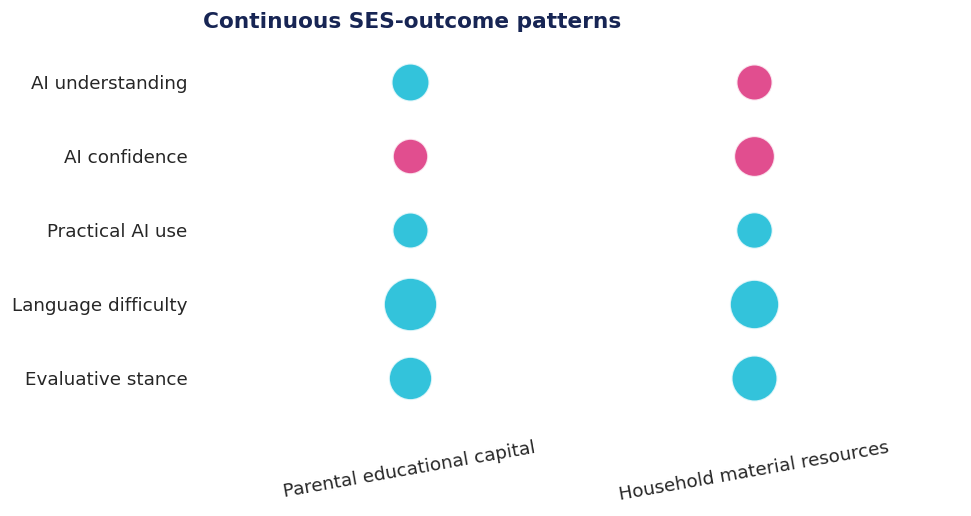

In [8]:
plot_association_matrix(associations)

course_display = course_tests.copy()
course_display['Lower SES with prior course'] = course_display.apply(
    lambda row: f"{int(row['lower_prior_course'])}/{int(row['lower_total'])}", axis=1
)
course_display['Higher SES with prior course'] = course_display.apply(
    lambda row: f"{int(row['higher_prior_course'])}/{int(row['higher_total'])}", axis=1
)
course_display['Fisher p'] = course_display['p_value'].map(lambda x: f'{x:.3f}')
display(course_display[[
    'SES dimension', 'Lower SES with prior course',
    'Higher SES with prior course', 'Fisher p'
]].style.hide_index())

rho_row = associations.loc[associations['p_value'].idxmin()]
edu_course = course_tests.iloc[0]
display(Markdown(
    "**Interpretation.** Students with more **parental educational capital** tend to report **less language difficulty**. "
    f"Prior AI-course experience is also uneven: **{int(edu_course['higher_prior_course'])}/{int(edu_course['higher_total'])}** "
    f"students in the higher parental-education half report a prior course, compared with "
    f"**{int(edu_course['lower_prior_course'])}/{int(edu_course['lower_total'])}** in the lower half. "
    "This suggests that **access to earlier AI learning** may be intertwined with socioeconomic background and should be "
    "recorded carefully in future studies."
))


<div class="page-break"></div>

# Summary for non-technical review

In [9]:
display(Markdown(f'''
## Main findings

1. **Conceptual understanding is the clearest teaching opportunity.** Students perform least well on recognising the **black-box nature of AI** and its **social or ethical limits**, while reporting stronger confidence in prompting and responding to AI-related issues. Teaching should therefore check understanding directly, not rely on confidence alone.

2. **The clearest SES pattern concerns language, not AI scores.** Students with higher **parental educational capital** report less language difficulty. This suggests that language support may be an important route for reducing unequal learning experiences.

3. **AI literacy looks broadly similar across the SES halves.** Within these 20 students, AI understanding and confidence do not show a clear separation between lower and higher groups on either EFA-based SES dimension. The small sample means that modest differences may still be present.

4. **Prior learning opportunities are uneven.** Prior AI-course experience is more common in the higher parental-education half. Future work should record this exposure so that **earlier access to AI learning** is not mistaken for an SES effect.

5. **The mediator findings are exploratory.** The current analysis retains **practical AI use**, **language difficulty**, and **evaluative stance**. They help describe learning experiences that may connect socioeconomic background with AI literacy, but this small cross-sectional sample cannot establish a causal pathway.
'''))



## Main findings

1. **Conceptual understanding is the clearest teaching opportunity.** Students perform least well on recognising the **black-box nature of AI** and its **social or ethical limits**, while reporting stronger confidence in prompting and responding to AI-related issues. Teaching should therefore check understanding directly, not rely on confidence alone.

2. **The clearest SES pattern concerns language, not AI scores.** Students with higher **parental educational capital** report less language difficulty. This suggests that language support may be an important route for reducing unequal learning experiences.

3. **AI literacy looks broadly similar across the SES halves.** Within these 20 students, AI understanding and confidence do not show a clear separation between lower and higher groups on either EFA-based SES dimension. The small sample means that modest differences may still be present.

4. **Prior learning opportunities are uneven.** Prior AI-course experience is more common in the higher parental-education half. Future work should record this exposure so that **earlier access to AI learning** is not mistaken for an SES effect.

5. **The mediator findings are exploratory.** The current analysis retains **practical AI use**, **language difficulty**, and **evaluative stance**. They help describe learning experiences that may connect socioeconomic background with AI literacy, but this small cross-sectional sample cannot establish a causal pathway.
